# Decisões de modelagem — guia explicado

> Complemento de `notebooks/04_modelos_completo.ipynb`. Aquele notebook executa o pipeline e
> apresenta os resultados; **este aqui explica por que cada decisão foi tomada** e
> mostra os experimentos que sustentam as escolhas — inclusive caminhos que testamos
> e descartamos.

Cada seção segue o mesmo formato: a pergunta, o experimento que a responde, e a
leitura do resultado. Todo o código roda: execute `Restart & Run All` para reproduzir
os números citados.

**Índice**

1. O que o `Pipeline` faz (e por que não dá para viver sem ele)
2. Treino, teste e validação cruzada: quem usa o quê
3. Por que o recall não é 100% nem no conjunto de treino
4. `StratifiedKFold` ou `KFold`?
5. `cross_val_score` ou `GridSearchCV`?
6. A escolha do scaler: por que "robusto" não quer dizer "melhor"
7. Por que o mapa de correlação não basta para escolher variáveis
8. Ruído ou melhora real? Como saber
9. Outliers: as alternativas que não usamos
10. KNN: o que ele oferece e o que não
11. `clone()`: por que criar modelos em fábrica
12. Erros complementares e comitê de modelos
13. Desempate entre modelos empatados: SVM × regressão logística
14. Escolher o limiar: custo declarado e regra de 1 erro-padrão
15. PCA ou seleção de variáveis? Duas respostas para o mesmo problema
16. SHAP: reprodutibilidade e o que é estável
17. SHAP × permutação: por que discordam sobre `area_se`
18. O que um coeficiente mede depende do scaler
19. Boas práticas de notebook que este trabalho ensinou
20. Checklist de vazamento

## 0. Preparação

Carregamos a base limpa e refazemos a mesma divisão do notebook 04, para que os
números batam.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict,
                                     StratifiedKFold, KFold, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
TARGET = 'diagnosis'

df = pd.read_csv('../data/processed/breast_cancer_wisconsin_clean.csv')
x = df.drop(columns=[TARGET])
y = df[TARGET]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

print(f'Base:   {len(df)} exames, {x.shape[1]} variáveis')
print(f'Treino: {len(y_train)} exames ({int((y_train == 1).sum())} malignos)')
print(f'Teste:  {len(y_test)} exames ({int((y_test == 1).sum())} malignos)')

Base:   569 exames, 30 variáveis
Treino: 455 exames (170 malignos)
Teste:  114 exames (42 malignos)


## 1. O que o `Pipeline` faz (e por que não dá para viver sem ele)

**A pergunta.** Por que escrever `Pipeline([('scaler', ...), ('clf', ...)])` em vez de
simplesmente padronizar os dados e depois treinar?

**O contrato.** O `Pipeline` encadeia transformações e um modelo final num objeto único
que se comporta como um modelo só. A regra: todos os passos **menos o último** precisam
ter `fit` e `transform`; o último precisa ter `fit` e `predict`.

No `fit`, ele percorre a cadeia chamando `fit_transform`; no `predict`, chama apenas
`transform`. Essa assimetria é o ponto central — os parâmetros da padronização são
aprendidos **só** no treino e reaplicados no teste.

```
fit:      x_train ──> scaler.fit_transform() ──> clf.fit()
predict:  x_test  ──> scaler.transform()     ──> clf.predict()
```

**Por que importa.** Sem pipeline, três erros ficam fáceis de cometer e nenhum deles
levanta exceção: esquecer de escalar o teste, usar `fit_transform` no teste (vazamento),
ou passar o conjunto errado ao `predict`. Você só percebe por um número estranho — ou,
pior, bom demais.

A demonstração abaixo mede o tamanho do problema.

In [2]:
from sklearn.metrics import precision_score

resultados = []

# forma CORRETA: scaler aprendido no treino, aplicado nos dois
scaler_ok = StandardScaler().fit(x_train)
modelo_ok = SVC(C=10, random_state=RANDOM_STATE).fit(scaler_ok.transform(x_train), y_train)
pred = modelo_ok.predict(scaler_ok.transform(x_test))
resultados.append(('correto', pred))

# erro 1: esquecer de escalar o teste
resultados.append(('esqueceu de escalar o teste', modelo_ok.predict(x_test)))

# erro 2: ajustar o scaler na base inteira (o scaler "viu" o teste)
scaler_vaza = StandardScaler().fit(x)
modelo_vaza = SVC(C=10, random_state=RANDOM_STATE).fit(scaler_vaza.transform(x_train), y_train)
resultados.append(('scaler ajustado na base toda', modelo_vaza.predict(scaler_vaza.transform(x_test))))

print(f'{"":30s} {"acurácia":>9s} {"recall":>8s} {"precisão":>9s}')
for nome, pred in resultados:
    print(f'{nome:30s} {accuracy_score(y_test, pred):9.4f} '
          f'{recall_score(y_test, pred):8.4f} {precision_score(y_test, pred):9.4f}')

                                acurácia   recall  precisão
correto                           0.9737   0.9286    1.0000
esqueceu de escalar o teste       0.3684   1.0000    0.3684
scaler ajustado na base toda      0.9737   0.9286    1.0000


**Como ler — e este resultado é melhor do que parece.**

O erro de **não escalar o teste** produz `recall = 1,0000`. Lido isoladamente, parece o
melhor modelo do notebook. Mas a acurácia desaba para 0,37 e a precisão para 0,37: o
modelo passou a classificar **quase tudo como maligno**. Os dados de teste chegam numa
escala que ele nunca viu, e todos caem do mesmo lado da fronteira.

Guarde esse caso. É a demonstração mais limpa de por que **recall sozinho não basta**:
um classificador que responde "maligno" para todo mundo tem recall perfeito e utilidade
zero. É por isso que o notebook 04 reporta recall, precisão, f1 e AUC juntos, e mantém o
`DummyClassifier` como piso.

O erro de **ajustar o scaler na base toda** dá, aqui, exatamente o mesmo resultado que a
forma correta. E isso é precisamente o que o torna perigoso: com 569 exames homogêneos,
a média e o desvio calculados com ou sem as 114 linhas de teste são quase idênticos, e o
vazamento não aparece. Em bases menores, mais heterogêneas, ou com pré-processamentos que
aprendem mais (imputação, seleção de variáveis, PCA), o mesmo descuido infla o resultado
sem deixar rastro.

A lição não é "esse vazamento é inofensivo" — é que **vazamento não se detecta pelo
resultado**. Se detecta pela estrutura do código. Por isso o `Pipeline`: ele torna o erro
impossível, em vez de detectável.

## 2. Treino, teste e validação cruzada: quem usa o quê

**A pergunta.** Se temos 114 exames separados para teste, por que as matrizes de
confusão do notebook 04 são calculadas sobre 455 linhas?

**A resposta.** São medições com finalidades diferentes.

| pergunta | conjunto | quantas vezes |
|---|---|---|
| Qual modelo, quais hiperparâmetros, qual limiar? | treino (455), por CV | quantas quiser |
| Quão bem o modelo escolhido funciona? | teste (114) | **uma vez só** |

Usar o teste para comparar modelos significa escolher o vencedor **com base nele** — e
a partir daí o número que ele produz deixa de ser uma estimativa honesta. É o que se
chama de queimar o conjunto de teste.

**O detalhe que confunde.** A matriz sobre 455 linhas não é "o modelo avaliado no que
ele decorou". O `cross_val_predict` devolve, para cada linha, a previsão do fold em que
ela ficou **de fora** do treinamento:

```
455 linhas → 5 folds de 91
rodada 1: treina em 364 → prevê os 91 do fold 1
...
rodada 5: treina em 364 → prevê os 91 do fold 5
                          └─ 455 previsões fora da amostra
```

In [3]:
modelo = Pipeline([('scaler', StandardScaler()),
                   ('clf', SVC(C=10, random_state=RANDOM_STATE))])

y_cv = cross_val_predict(modelo, x_train, y_train, cv=cv)
modelo.fit(x_train, y_train)
y_te = modelo.predict(x_test)

print('CV no treino (455 exames, 170 malignos)')
print(confusion_matrix(y_train, y_cv))
print(f'recall {recall_score(y_train, y_cv):.4f}  '
      f'-> {int(((y_train == 1) & (y_cv == 0)).sum())} falsos negativos em 170\n')

print('Teste (114 exames, 42 malignos)')
print(confusion_matrix(y_test, y_te))
print(f'recall {recall_score(y_test, y_te):.4f}  '
      f'-> {int(((y_test == 1) & (y_te == 0)).sum())} falsos negativos em 42')

CV no treino (455 exames, 170 malignos)
[[280   5]
 [  6 164]]
recall 0.9647  -> 6 falsos negativos em 170

Teste (114 exames, 42 malignos)
[[72  0]
 [ 3 39]]
recall 0.9286  -> 3 falsos negativos em 42


**Como ler.** A contagem absoluta de falsos negativos é maior no treino simplesmente
porque há 170 malignos ali contra 42 no teste. Em taxa, as duas medições são próximas —
e a do treino é **mais estável**, porque cada caso pesa 0,6 ponto de recall em vez de
2,4. Por isso ela serve para decidir, e a do teste serve para reportar.

Foi exatamente esse efeito que apareceu quando comparamos 30 × 16 variáveis: o que
parecia vitória no teste era **um único paciente** de diferença.

## 3. Por que o recall não é 100% nem no conjunto de treino

**A pergunta.** Se o modelo treina vendo o diagnóstico, não deveria acertar tudo?

**Primeiro:** o diagnóstico **não é uma variável de entrada**. O `x` tem 30 colunas e
`diagnosis` não está entre elas. O `y` é o gabarito, usado durante o `fit` para ajustar
parâmetros e descartado depois — no `predict` só entram as medidas.

**Segundo, e menos óbvio:** mesmo medindo no próprio treino, a maioria dos modelos não
chega a 100%.

In [4]:
modelos = {
    'SVM (C=10)':        Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))]),
    'LogReg':            Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=10000))]),
    'KNN (k=3)':         Pipeline([('s', StandardScaler()), ('c', KNeighborsClassifier(3))]),
    'KNN (k=1)':         Pipeline([('s', StandardScaler()), ('c', KNeighborsClassifier(1))]),
    'Árvore (sem poda)': Pipeline([('s', 'passthrough'), ('c', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
}

print(f'{"modelo":20s} | recall TREINO | recall TESTE')
print('-' * 54)
for nome, m in modelos.items():
    m.fit(x_train, y_train)
    print(f'{nome:20s} |    {recall_score(y_train, m.predict(x_train)):.4f}     '
          f'|   {recall_score(y_test, m.predict(x_test)):.4f}')

modelo               | recall TREINO | recall TESTE
------------------------------------------------------


SVM (C=10)           |    0.9706     |   0.9286


LogReg               |    0.9647     |   0.9286


KNN (k=3)            |    0.9588     |   0.8571
KNN (k=1)            |    1.0000     |   0.8810
Árvore (sem poda)    |    1.0000     |   0.9048


**Como ler.** O SVM erra nos mesmos dados em que treinou — e isso é intencional. O
parâmetro `C` regula o quanto o modelo aceita errar no treino em troca de uma fronteira
mais simples, que generaliza melhor. Um modelo que acerta 100% do treino **decorou**.

Os dois que chegam a 1,0000 confirmam: o KNN com `k=1` tem a si mesmo como vizinho mais
próximo (distância zero), e a árvore sem poda cresce até cada folha ter um único exame.
Repare que são justamente **os dois piores no teste**. Essa distância entre treino e
teste é a assinatura do overfitting.

**E se o diagnóstico entrasse mesmo como variável?** A célula abaixo mostra o cenário —
e por que resultado perfeito é motivo de desconfiança, não de comemoração.

In [5]:
x_train_vaza = x_train.copy(); x_train_vaza[TARGET] = y_train
x_test_vaza = x_test.copy();   x_test_vaza[TARGET] = y_test

m = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))])
m.fit(x_train_vaza, y_train)

print(f'com o alvo entre as variáveis -> recall treino: '
      f'{recall_score(y_train, m.predict(x_train_vaza)):.4f} | '
      f'recall teste: {recall_score(y_test, m.predict(x_test_vaza)):.4f}')
print('\nResultado perfeito em dados novos não acontece em problema real.')
print('Quando acontece, quase sempre alguma coluna carrega a resposta.')

com o alvo entre as variáveis -> recall treino: 1.0000 | recall teste: 1.0000

Resultado perfeito em dados novos não acontece em problema real.
Quando acontece, quase sempre alguma coluna carrega a resposta.


## 4. `StratifiedKFold` ou `KFold`?

**A pergunta.** O `KFold` simples não serviria?

Serve, roda sem erro. Mas com classes desbalanceadas (62,7% / 37,3%) e base pequena, a
proporção de cada classe oscila entre os folds — e isso entra como ruído na medição.

In [6]:
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)

comp = pd.DataFrame({
    'KFold': [y_train.iloc[val].mean() for _, val in kf.split(x_train, y_train)],
    'StratifiedKFold': [y_train.iloc[val].mean() for _, val in cv.split(x_train, y_train)],
}, index=[f'fold {i+1}' for i in range(5)]).round(4)
comp.loc['amplitude'] = (comp.max() - comp.min()).round(4)
print('Proporção de malignos em cada fold de validação:')
display(comp)

Proporção de malignos em cada fold de validação:


,KFold,StratifiedKFold
fold 1,0.3516,0.3736
fold 2,0.4286,0.3736
fold 3,0.3297,0.3736
fold 4,0.4176,0.3736
fold 5,0.3407,0.3736
amplitude,0.0989,0.0000


In [7]:
# a estratificação importa para a ESTABILIDADE da estimativa entre execuções:
# repetimos a validação cruzada com 30 embaralhamentos diferentes
modelo = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))])

medias = {'KFold': [], 'StratifiedKFold': []}
for seed in range(30):
    medias['KFold'].append(
        cross_val_score(modelo, x_train, y_train, scoring='recall',
                        cv=KFold(5, shuffle=True, random_state=seed)).mean())
    medias['StratifiedKFold'].append(
        cross_val_score(modelo, x_train, y_train, scoring='recall',
                        cv=StratifiedKFold(5, shuffle=True, random_state=seed)).mean())

for nome, vals in medias.items():
    print(f'{nome:16s} recall medio {np.mean(vals):.4f} | '
          f'variacao entre execucoes +-{np.std(vals):.4f}')

KFold            recall medio 0.9555 | variacao entre execucoes +-0.0105
StratifiedKFold  recall medio 0.9555 | variacao entre execucoes +-0.0098


**Como ler — com honestidade sobre o tamanho do efeito.**

A primeira tabela mostra o que a estratificação garante: a proporção de malignos é
**idêntica em todos os folds** (amplitude 0,0000), enquanto no `KFold` ela oscila quase
10 pontos percentuais entre o fold mais pobre e o mais rico.

A segunda célula mede se isso se traduz em medição mais estável. Repetindo a validação
cruzada com 30 embaralhamentos diferentes, a variação da estimativa é **ligeiramente
menor** com estratificação (±0,0098 contra ±0,0105) — uma vantagem real, mas modesta
nesta base.

Por que a diferença não é dramática aqui: 455 linhas divididas em 5 folds dão 91 exames
por fold, o suficiente para que o sorteio aleatório já chegue perto da proporção correta
na maioria das vezes. O ganho da estratificação cresce quando os folds são pequenos
(k alto, base pequena) ou quando o desbalanceamento é severo — com 5% de positivos, um
fold sem nenhum caso positivo deixa de ser hipótese remota.

**A recomendação continua sendo `StratifiedKFold`**, por uma razão que não é o desvio: ela
*garante* a composição dos folds em vez de depender da sorte. Em classificação não há
custo em usá-la, e o comportamento fica reprodutível por construção.

Três pontos práticos:

- **Se usar `KFold`, use `shuffle=True`.** Sem isso ele corta a base na ordem do arquivo;
  se o CSV estiver ordenado por algo correlacionado ao alvo, um fold pode ficar quase todo
  de uma classe.
- **O sklearn já estratifica sozinho.** Passar `cv=5` (um inteiro) para `cross_val_score`
  ou `GridSearchCV` com um classificador usa `StratifiedKFold` por padrão — sem shuffle.
  Escrever `KFold` explicitamente é *abrir mão* do comportamento padrão.
- **`KFold` é a escolha certa em regressão**, onde não há classe para estratificar.

## 5. `cross_val_score` ou `GridSearchCV`?

**A pergunta.** Precisamos rodar `cross_val_score` em cada modelo antes de fazer o
GridSearch?

**Não — seria trabalho duplicado.** O `GridSearchCV` *já faz* validação cruzada
internamente: ele testa cada combinação de hiperparâmetros exatamente assim, nos mesmos
folds.

A distinção:

- `cross_val_score` → **mede** uma configuração fixa. Serve para comparar modelos já
  definidos.
- `GridSearchCV` → **escolhe** a configuração, e usa CV para isso.

A ordem correta é: grid para tunar cada modelo → `cross_val_score` (ou a tabela do
notebook 04) para comparar os campeões → teste, uma vez, no vencedor.

In [8]:
grid = GridSearchCV(
    Pipeline([('scaler', 'passthrough'), ('clf', KNeighborsClassifier())]),
    {'scaler': [StandardScaler(), MinMaxScaler()],
     'clf__n_neighbors': [3, 5, 7, 9]},
    scoring='recall', cv=cv, n_jobs=-1).fit(x_train, y_train)

print('melhor configuração:', grid.best_params_)
print(f'recall CV do melhor: {grid.best_score_:.4f}')
print(f'combinações avaliadas: {len(grid.cv_results_["params"])} '
      f'(cada uma com {cv.get_n_splits()} folds = '
      f'{len(grid.cv_results_["params"]) * cv.get_n_splits()} treinos)')

melhor configuração: {'clf__n_neighbors': 3, 'scaler': MinMaxScaler()}
recall CV do melhor: 0.9412
combinações avaliadas: 8 (cada uma com 5 folds = 40 treinos)


**Uma ressalva honesta.** O `best_score_` é levemente otimista: é o **máximo** entre
muitas combinações avaliadas nos mesmos folds, então um pouco de sorte entra no número.
O procedimento rigoroso seria *nested cross-validation* (um CV externo envolvendo o
grid). Para este trabalho é exagero — basta manter o teste separado, que é a estimativa
honesta, e declarar a limitação.

## 6. A escolha do scaler: por que "robusto" não quer dizer "melhor"

**A pergunta.** Com tantos outliers, o `RobustScaler` não é a escolha natural?

O raciocínio parece bom: média e desvio padrão são puxados por valores extremos,
enquanto mediana e IQR não. É verdade — **mas isso protege os parâmetros da
transformação, não os dados.**

O `RobustScaler` não remove outlier nenhum. E como o IQR de uma coluna de cauda pesada é
bem menor que o desvio padrão, dividir por ele **empurra os extremos para ainda mais
longe**.

In [9]:
col = 'area_se'   # a coluna mais assimétrica da base
linhas = []
for nome, sc in [('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler()),
                 ('MinMaxScaler', MinMaxScaler())]:
    v = pd.Series(sc.fit_transform(x_train)[:, list(x.columns).index(col)])
    linhas.append({'scaler': nome, 'mediana': round(v.median(), 3),
                   'percentil 99': round(v.quantile(.99), 3), 'máximo': round(v.max(), 3)})
display(pd.DataFrame(linhas).set_index('scaler'))

print(f'Efeito no desempenho (recall CV, coluna completa):\n')
for nome, sc in [('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler()),
                 ('MinMaxScaler', MinMaxScaler())]:
    for mnome, clf in [('SVM', SVC(random_state=RANDOM_STATE)), ('KNN k=5', KNeighborsClassifier(5))]:
        p = Pipeline([('s', sc), ('c', clf)])
        s = cross_val_score(p, x_train, y_train, cv=cv, scoring='recall')
        print(f'  {nome:16s} {mnome:8s} recall {s.mean():.4f} ± {s.std():.3f}')

,mediana,percentil 99,máximo
scaler,,,
StandardScaler,-0.340,3.019,10.364
RobustScaler,0.000,5.894,18.788
MinMaxScaler,0.034,0.337,1.000


Efeito no desempenho (recall CV, coluna completa):

  StandardScaler   SVM      recall 0.9471 ± 0.034


  StandardScaler   KNN k=5  recall 0.9176 ± 0.034
  RobustScaler     SVM      recall 0.9471 ± 0.034


  RobustScaler     KNN k=5  recall 0.9294 ± 0.030
  MinMaxScaler     SVM      recall 0.9529 ± 0.030


  MinMaxScaler     KNN k=5  recall 0.9353 ± 0.043


**Como ler.** O `RobustScaler` manda o ponto extremo de `area_se` para quase o dobro da
distância que o `StandardScaler` produz. Na distância euclidiana do KNN, esse ponto vira
um vizinho absurdamente distante de todo mundo. O "robusto" protegeu a estatística e
piorou a geometria.

O `MinMaxScaler` limita **toda** variável a [0, 1]: nenhuma coluna contribui com mais de
1 unidade para a distância, por mais assimétrica que seja. Para métodos baseados em
distância, essa garantia costuma importar mais que a resistência a extremos.

**Quando usar cada um:**

- `StandardScaler` — dados aproximadamente simétricos; obrigatório quando o método
  pressupõe média zero (PCA, regularização comparável entre variáveis).
- `RobustScaler` — quando há outliers que você *sabe* serem erro de medição e que
  distorceriam média/desvio, mas que não pode remover.
- `MinMaxScaler` — quando a faixa limitada importa: KNN, SVM-RBF, redes neurais.

**A conclusão prática** foi parar de decidir no argumento e colocar o scaler na grade do
`GridSearchCV`, como mais um hiperparâmetro. No notebook 04, o KNN e a regressão logística
têm um único vencedor, cada um com um scaler diferente (MinMax e Robust). Para o SVM, os
três scalers empatam no recall máximo, e o vencedor aparente depende só da ordem da
grade, porque o GridSearch desempata pelo primeiro da lista. Não existe resposta
única — e, às vezes, a resposta honesta é "tanto faz". Detalhe técnico: o
`gamma='scale'` do SVC é calculado a partir da variância dos dados, então o gamma efetivo
**muda junto com o scaler**. Mais uma razão para testar o par em conjunto.

## 7. Por que o mapa de correlação não basta para escolher variáveis

**A pergunta.** Posso escolher as variáveis pelas mais correlacionadas com o alvo?

**Não.** A correlação é univariada: mede cada variável isolada contra o alvo e **não
enxerga redundância entre elas**. O experimento abaixo mostra o custo disso.

In [10]:
corr_y = x_train.corrwith(y_train).abs()
cm = x_train.corr().abs()

top10 = corr_y.sort_values(ascending=False).head(10).index.tolist()

# seleção que remove redundância: de cada grupo acima de 0,90, mantém a mais ligada ao alvo
keep = []
for c in corr_y.sort_values(ascending=False).index:
    if all(cm.loc[c, k] < 0.9 for k in keep):
        keep.append(c)
keep16 = [k for k in keep if corr_y[k] > 0.2]

for nome, cols in [('todas as 30', list(x_train.columns)),
                   ('top 10 por correlação', top10),
                   (f'sem redundância ({len(keep16)})', keep16)]:
    for mnome, clf in [('SVM', SVC(random_state=RANDOM_STATE)), ('KNN', KNeighborsClassifier(5))]:
        p = Pipeline([('s', StandardScaler()), ('c', clf)])
        s = cross_val_score(p, x_train[cols], y_train, cv=cv, scoring='roc_auc')
        print(f'{nome:26s} {mnome:4s} n={len(cols):2d}  AUC {s.mean():.4f}')

todas as 30                SVM  n=30  AUC 0.9949


todas as 30                KNN  n=30  AUC 0.9871
top 10 por correlação      SVM  n=10  AUC 0.9798


top 10 por correlação      KNN  n=10  AUC 0.9671


sem redundância (16)       SVM  n=16  AUC 0.9958
sem redundância (16)       KNN  n=16  AUC 0.9913


**Como ler.** O "top 10 por correlação" é **o pior conjunto dos três** — exatamente o que
o heatmap sozinho sugeriria. O motivo: aquelas dez variáveis são praticamente a mesma
informação repetida. `radius_mean` e `perimeter_mean` têm correlação 0,998 entre si
porque perímetro é função matemática do raio.

Para KNN e SVM isso não é só ineficiência: informação duplicada vira **peso multiplicado
na distância euclidiana**. Três colunas medindo tamanho fazem o "tamanho do núcleo" pesar
três vezes mais que textura ou simetria.

**O processo correto tem quatro passos:**

1. Excluir por domínio (identificadores, colunas que vazam o alvo) — não por estatística.
2. Remover redundância: de cada grupo correlacionado, manter a mais ligada ao alvo.
3. Descartar o que não informa (correlação com o alvo próxima de zero).
4. **Validar com o modelo**, por CV — é o que o heatmap nunca responde.

E uma ressalva: a correlação de Pearson mede relação **linear**. Uma variável com
correlação 0,01 pode ser útil numa interação não linear que o kernel RBF captura. Foi o
que aconteceu com `texture_worst`, que lidera a importância no SHAP com correlação de
apenas 0,46.

## 8. Ruído ou melhora real? Como saber

**A pergunta.** Mudei algo e a acurácia subiu de 0,9561 para 0,9649. Melhorou?

Provavelmente não. Em 114 exames de teste, **cada caso vale 0,88 ponto percentual** — uma
diferença de 0,88 pp é literalmente um paciente. O teste abaixo repete a comparação em 20
divisões diferentes.

In [11]:
def avalia(cols, seed):
    xtr, xte, ytr, yte = train_test_split(x[cols], y, test_size=0.2,
                                          random_state=seed, stratify=y)
    p = Pipeline([('s', RobustScaler()), ('c', SVC(random_state=RANDOM_STATE))]).fit(xtr, ytr)
    return accuracy_score(yte, p.predict(xte))

difs = np.array([avalia(keep16, s) - avalia(list(x.columns), s) for s in range(20)])

print(f'30 variáveis venceu em {(difs < 0).sum()} splits')
print(f'{len(keep16)} variáveis venceu em {(difs > 0).sum()} splits')
print(f'empate em {(difs == 0).sum()}')
print(f'\ndiferença média: {difs.mean():+.4f} (desvio {difs.std():.4f})')

30 variáveis venceu em 10 splits
16 variáveis venceu em 4 splits
empate em 6

diferença média: -0.0061 (desvio 0.0124)


**A regra.** Se a diferença entre dois modelos é **menor que o desvio padrão da validação
cruzada**, você não pode afirmar que um é melhor. Sempre reporte o `±`.

E prefira a validação cruzada ao split único para comparar: ela usa todas as linhas de
treino e produz um desvio que diz quanto confiar na diferença.

**Como reportar um empate** sem perder o trabalho feito: em vez de "a seleção melhorou
1%", escreva "a seleção manteve o desempenho dentro da margem de erro usando metade das
variáveis, o que reduz custo de coleta e melhora a interpretabilidade". É honesto e
continua sendo um resultado.

## 9. Outliers: as alternativas que não usamos

O notebook 04 mostra por que **não removemos** os outliers: eles são majoritariamente
malignos e removê-los derruba o recall. Mas remover não é a única opção — estas são as
alternativas, em ordem de preferência para este problema.

**a) Padronizar (o que fizemos).** Resolve a maior parte do problema para modelos
baseados em distância, sem descartar nenhum exame.

**b) Winsorização (clipping).** Limita os extremos sem perder linhas. Os limites precisam
ser calculados no treino e aplicados no teste.

**c) Transformação log.** As colunas `_se` são as mais assimétricas; `np.log1p` aproxima
da normal e dissolve os extremos naturalmente.

**d) Remoção.** Só para valores *impossíveis* — negativos numa medida de área, por
exemplo. Verificamos: não há nenhum nesta base.

In [12]:
cols_se = [c for c in x_train.columns if c.endswith('_se')]

def winsoriza(treino, teste, limites=(0.01, 0.99)):
    lo, hi = treino.quantile(limites[0]), treino.quantile(limites[1])   # limites DO TREINO
    return treino.clip(lo, hi, axis=1), teste.clip(lo, hi, axis=1)

xtr_w, xte_w = winsoriza(x_train, x_test)
xtr_log, xte_log = x_train.copy(), x_test.copy()
xtr_log[cols_se] = np.log1p(xtr_log[cols_se])
xte_log[cols_se] = np.log1p(xte_log[cols_se])

for nome, (xtr, _) in {'original': (x_train, x_test),
                       'winsorizado (1%-99%)': (xtr_w, xte_w),
                       'log nas colunas _se': (xtr_log, xte_log)}.items():
    p = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))])
    s = cross_val_score(p, xtr, y_train, cv=cv, scoring='recall')
    print(f'{nome:24s} recall {s.mean():.4f} ± {s.std():.3f}')

print(f'\nAssimetria média das colunas _se: '
      f'original {x_train[cols_se].skew().mean():.2f} -> '
      f'após log {xtr_log[cols_se].skew().mean():.2f}')

original                 recall 0.9647 ± 0.029


winsorizado (1%-99%)     recall 0.9647 ± 0.029
log nas colunas _se      recall 0.9647 ± 0.029

Assimetria média das colunas _se: original 3.15 -> após log 2.08


**Como ler.** A transformação log reduz bastante a assimetria, mas o desempenho fica
praticamente igual — mais uma confirmação de que o SVM com kernel RBF já lida bem com
distribuições assimétricas, desde que os dados estejam padronizados.

O ponto metodológico que vale levar: **os limites da winsorização vêm do treino**. Calcular
os percentis na base inteira seria vazamento, pelo mesmo motivo que o scaler.

## 10. KNN: o que ele oferece e o que não

**A pergunta.** O KNN tem a maior acurácia. Por que não é o modelo escolhido?

**A razão decisiva é a granularidade das probabilidades.** Com `k=3`, o `predict_proba`
só consegue devolver quatro valores — e isso inviabiliza o ajuste de limiar, que é o
mecanismo central da nossa estratégia.

In [13]:
knn = Pipeline([('s', MinMaxScaler()),
                ('c', KNeighborsClassifier(3, metric='manhattan'))]).fit(x_train, y_train)
log = Pipeline([('s', RobustScaler()),
                ('c', LogisticRegression(C=1, class_weight='balanced',
                                         max_iter=10000, random_state=RANDOM_STATE))]).fit(x_train, y_train)

pk, pl = knn.predict_proba(x_test)[:, 1], log.predict_proba(x_test)[:, 1]
print(f'KNN    - probabilidades distintas: {len(np.unique(pk))} -> {np.round(np.unique(pk), 3)}')
print(f'LogReg - probabilidades distintas: {len(np.unique(pl))}\n')

print('recall no teste conforme o limiar:')
print('limiar | KNN    | LogReg')
for t in [0.5, 0.4, 0.3, 0.2]:
    print(f'  {t:.1f}  | {recall_score(y_test, (pk >= t).astype(int)):.4f} '
          f'| {recall_score(y_test, (pl >= t).astype(int)):.4f}')

KNN    - probabilidades distintas: 4 -> [0.    0.333 0.667 1.   ]
LogReg - probabilidades distintas: 114

recall no teste conforme o limiar:
limiar | KNN    | LogReg
  0.5  | 0.9286 | 0.9524
  0.4  | 0.9286 | 0.9524
  0.3  | 0.9524 | 0.9762
  0.2  | 0.9524 | 0.9762


**Como ler.** Mover o limiar de 0,5 para 0,4 **não muda nada** no KNN: não existe
probabilidade nesse intervalo. É também o que explica sua AUC mais baixa — a curva ROC
tem apenas quatro pontos. Um modelo que não gradua confiança não responde ao ajuste de
limiar.

**Onde o KNN é genuinamente bom:**

- **Não assume forma da fronteira.** Se as classes formassem ilhas separadas no espaço,
  ele pegaria e um modelo linear não. Aqui a fronteira é quase linear, então a
  flexibilidade não se paga.
- **Não tem treino.** O `fit` só guarda os dados — útil quando a base muda com frequência.
- **Poucos hiperparâmetros.**
- **Explicação por casos análogos** — a vantagem que vale citar no relatório.

In [14]:
esc = MinMaxScaler().fit(x_train)
nn = NearestNeighbors(n_neighbors=3, metric='manhattan').fit(esc.transform(x_train))

for pos in [0, 1]:
    d, idx = nn.kneighbors(esc.transform(x_test.iloc[[pos]]))
    rot = {0: 'benigno', 1: 'maligno'}
    print(f'exame de teste {x_test.index[pos]} (real: {rot[int(y_test.iloc[pos])]})')
    for i, dd in zip(idx[0], d[0]):
        print(f'   vizinho {x_train.index[i]:4d} | {rot[int(y_train.iloc[i])]:8s} | distância {dd:.3f}')
    print()

exame de teste 120 (real: benigno)
   vizinho  271 | benigno  | distância 0.919
   vizinho  527 | benigno  | distância 1.071
   vizinho   48 | benigno  | distância 1.207

exame de teste 250 (real: maligno)
   vizinho  535 | maligno  | distância 1.772
   vizinho  302 | maligno  | distância 2.082
   vizinho    2 | maligno  | distância 2.131



**Como ler.** "Este exame foi classificado como benigno porque os três casos mais
parecidos da base eram benignos." Num contexto clínico isso é mais tangível que "o
coeficiente de `texture_worst` é 1,66" — o médico pode abrir os prontuários e comparar.
É raciocínio por precedente, que é como boa parte da medicina funciona.

**A conclusão defensável para o relatório:** o KNN atinge a maior acurácia, mas sua
granularidade de probabilidade inviabiliza o ajuste de limiar, que é o mecanismo central
para priorizar sensibilidade. Por isso o modelo final recai sobre SVM ou regressão
logística. Isso é bem mais forte que "o KNN foi pior".

## 11. `clone()`: por que criar modelos em fábrica

**A pergunta.** Por que não reaproveitar o mesmo objeto de pipeline em dois treinos?

Porque `fit` **sobrescreve** o estado anterior. Treinar duas vezes o mesmo objeto deixa
você com duas variáveis apontando para o mesmo modelo — e a comparação sai idêntica, sem
erro algum.

In [15]:
from sklearn.base import clone

base = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))])
metade = x_train.iloc[:200]

# ERRADO: o mesmo objeto treinado duas vezes
m1 = base.fit(x_train, y_train)
m2 = base.fit(metade, y_train.iloc[:200])
print(f'mesmo objeto?  {m1 is m2}  -> recall m1: {recall_score(y_test, m1.predict(x_test)):.4f} '
      f'| recall m2: {recall_score(y_test, m2.predict(x_test)):.4f}')

# CERTO: clone() copia a configuração, não o que foi aprendido
m3 = clone(base).fit(x_train, y_train)
m4 = clone(base).fit(metade, y_train.iloc[:200])
print(f'mesmo objeto?  {m3 is m4}  -> recall m3: {recall_score(y_test, m3.predict(x_test)):.4f} '
      f'| recall m4: {recall_score(y_test, m4.predict(x_test)):.4f}')

mesmo objeto?  True  -> recall m1: 0.9048 | recall m2: 0.9048
mesmo objeto?  False  -> recall m3: 0.9286 | recall m4: 0.9048


**Como ler.** No caso errado, `m1` e `m2` são o mesmo objeto e produzem o mesmo número —
o bug não gera exceção, só um resultado sem sentido. Com `clone()`, os dois treinos são
independentes.

É exatamente o que `GridSearchCV` e `cross_val_score` fazem internamente a cada fold —
por isso eles nunca sofrem desse problema. Uma função fábrica (`def novo_pipe(): return
Pipeline(...)`) resolve igual; `clone()` só deixa mais explícito que a configuração é a
mesma.

## 12. Erros complementares e comitê de modelos

**A pergunta.** Se dois modelos erram, será que erram nos mesmos exames?

Se erram nos mesmos, combiná-los não traz ganho. Se erram em exames diferentes, há espaço
para um comitê.

In [16]:
modelos_cmp = {
    'SVM': Pipeline([('s', StandardScaler()), ('c', SVC(C=10, random_state=RANDOM_STATE))]),
    'KNN': Pipeline([('s', MinMaxScaler()), ('c', KNeighborsClassifier(3, metric='manhattan'))]),
    'LogReg': Pipeline([('s', RobustScaler()),
                        ('c', LogisticRegression(C=1, class_weight='balanced',
                                                 max_iter=10000, random_state=RANDOM_STATE))]),
}
fn = {}
for nome, m in modelos_cmp.items():
    m.fit(x_train, y_train)
    fn[nome] = set(y_test[(y_test == 1) & (m.predict(x_test) == 0)].index)
    print(f'{nome:7s} falsos negativos: {sorted(fn[nome])}')

todos = set.intersection(*fn.values())
uniao = set.union(*fn.values())
print(f'\nerrados por TODOS os modelos: {sorted(todos)}')
print(f'regra "maligno se QUALQUER um disser maligno" -> {len(todos)} falsos negativos')
print(f'(contra {min(len(v) for v in fn.values())} do melhor modelo isolado)')

SVM     falsos negativos: [73, 99, 205]
KNN     falsos negativos: [73, 205, 385]
LogReg  falsos negativos: [73, 190]

errados por TODOS os modelos: [73]
regra "maligno se QUALQUER um disser maligno" -> 1 falsos negativos
(contra 2 do melhor modelo isolado)


**Como ler.** Os erros divergem parcialmente: há exames que só um modelo perde. Uma regra
de união (classificar como maligno se qualquer modelo disser maligno) reduz os falsos
negativos — ao custo de mais falsos positivos, o câmbio que já conhecemos.

Se quisessem explorar isso formalmente, o caminho é o `VotingClassifier` com
`voting='soft'`, avaliado pela mesma validação cruzada. Não incluímos no trabalho para não
alongar, mas fica registrado como extensão natural.

Os exames errados por **todos** os modelos são os casos genuinamente difíceis — provável
sobreposição morfológica entre benigno e maligno nessas 30 medidas. É o limite do que
qualquer classificador sobre essas variáveis consegue.

## 13. Desempate entre modelos empatados: SVM × regressão logística

**A pergunta.** O SVM e a regressão logística tiveram exatamente o mesmo recall em
validação cruzada (0,9647). Como escolher?

Quando o critério principal empata dentro da margem de ruído, a escolha passa a se
apoiar em critérios secundários. O importante é **declará-los**, em vez de escolher
pelo hábito ou pela ordem em que os modelos foram testados — "mantemos o SVM por
coerência com a análise" é dependência de caminho, não argumento.

In [17]:
import time
from sklearn.model_selection import cross_validate

candidatos = {
    'SVM': Pipeline([('s', StandardScaler()),
                     ('c', SVC(C=10, probability=True, random_state=RANDOM_STATE))]),
    'Regressão Logística': Pipeline([('s', RobustScaler()),
                                     ('c', LogisticRegression(C=1, class_weight='balanced',
                                                              max_iter=10000, random_state=RANDOM_STATE))]),
}

linhas = []
for nome, m in candidatos.items():
    r = cross_validate(m, x_train, y_train, cv=cv, scoring=['recall', 'roc_auc'])
    t0 = time.perf_counter()
    for _ in range(10):
        m.fit(x_train, y_train)
    linhas.append({'modelo': nome,
                   'recall': f"{r['test_recall'].mean():.4f} ± {r['test_recall'].std():.3f}",
                   'AUC': f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.3f}",
                   'tempo de treino (ms)': round((time.perf_counter() - t0) / 10 * 1000, 1)})
display(pd.DataFrame(linhas).set_index('modelo'))

,recall,AUC,tempo de treino (ms)
modelo,,,
SVM,0.9647 ± 0.029,0.9935 ± 0.006,28.3
Regressão Logística,0.9647 ± 0.022,0.9953 ± 0.004,19.4


**Como ler.** Recall idêntico; a logística tem AUC ligeiramente maior e **mais estável**
(desvio menor). A AUC importa aqui porque mede a qualidade do *ordenamento* das
probabilidades — e é exatamente esse ordenamento que o ajuste de limiar explora.

Os critérios que de fato desempatam:

- **Interpretabilidade por construção.** Cada variável tem um coeficiente com sinal e
  magnitude. No SVM com kernel RBF, explicar a decisão exige aproximações como o SHAP.
- **Probabilidades nativas.** A regressão logística produz probabilidades diretamente.
  O `SVC` precisa de `probability=True`, que faz uma calibração interna extra (e emite
  aviso de depreciação nas versões recentes do scikit-learn).

**Um argumento que *não* se sustenta: velocidade.** É comum dizer que a logística
"treina muito mais rápido". Nesta base, com 455 linhas, a diferença medida acima é da
ordem de milissegundos por treino, e varia de uma execução para outra — irrelevante. Ela passaria a importar com centenas de milhares de
exames, mas não é um critério legítimo para este trabalho. Vale a regra geral: todo
argumento de desempate precisa ser medido, não presumido.

## 14. Escolher o limiar: custo declarado e regra de 1 erro-padrão

**A pergunta.** Baixar o limiar aumenta o recall e também os falsos alarmes. Até onde
baixar? Por que 0,35, e não 0,25 ou 0,15?

**A resposta curta:** a tecnologia não decide isso sozinha. O limiar depende de uma
premissa sobre custos — **quantos falsos alarmes vale a pena aceitar para não deixar
passar um câncer**. Chamamos essa razão de `CUSTO_FN`. Declarada a premissa, o limiar sai
da minimização de `CUSTO_FN × FN + FP`.

**Dois cuidados que mudam o resultado:**

1. **Uma única validação cruzada exagera as diferenças.** Entre limiares vizinhos, a
   diferença costuma ser de um ou dois exames. Repetimos a CV com 20 embaralhamentos e
   usamos a média.
2. **A curva de custo pode ser plana.** Quando vários limiares têm custo dentro da
   margem de erro do mínimo, escolher o mínimo exato é escolher ruído. A **regra de 1
   erro-padrão** (Breiman et al., 1984) resolve: entre os limiares estatisticamente
   equivalentes ao mínimo, adota o mais conservador.

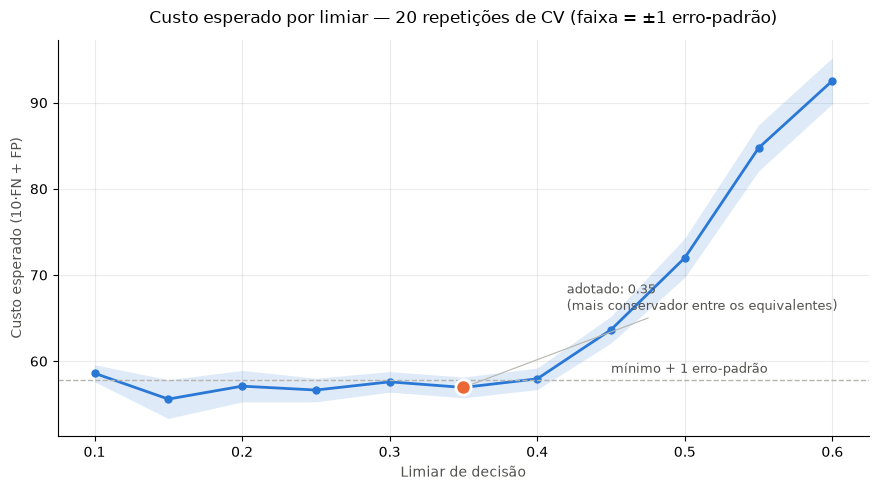

mínimo em 0.15 | equivalentes: [0.15, 0.2, 0.25, 0.3, 0.35] | adotado: 0.35

Sensibilidade à premissa:
   CUSTO_FN =  3  ->  limiar 0.40
   CUSTO_FN =  5  ->  limiar 0.40
   CUSTO_FN =  8  ->  limiar 0.40
   CUSTO_FN = 10  ->  limiar 0.35
   CUSTO_FN = 12  ->  limiar 0.15
   CUSTO_FN = 15  ->  limiar 0.15
   CUSTO_FN = 20  ->  limiar 0.10


In [18]:
AZUL, LARANJA, TINTA2 = '#2a78d6', '#eb6834', '#52514e'

modelo_lr = Pipeline([('s', RobustScaler()),
                      ('c', LogisticRegression(C=1, class_weight='balanced',
                                               max_iter=10000, random_state=RANDOM_STATE))])
LIMIARES = np.round(np.arange(0.10, 0.61, 0.05), 2)
N_REP = 20

fn_rep = np.zeros((N_REP, len(LIMIARES)))
fp_rep = np.zeros((N_REP, len(LIMIARES)))
for r in range(N_REP):
    prob = cross_val_predict(modelo_lr, x_train, y_train, method='predict_proba',
                             cv=StratifiedKFold(5, shuffle=True, random_state=r))[:, 1]
    for j, t in enumerate(LIMIARES):
        fn_rep[r, j] = ((y_train == 1) & (prob < t)).sum()
        fp_rep[r, j] = ((y_train == 0) & (prob >= t)).sum()


def escolhe_limiar(custo_fn):
    custo = custo_fn * fn_rep + fp_rep
    media, ep = custo.mean(axis=0), custo.std(axis=0, ddof=1) / np.sqrt(N_REP)
    j_min = int(np.argmin(media))
    equiv = [j for j in range(len(LIMIARES)) if media[j] <= media[j_min] + ep[j_min]]
    return media, ep, j_min, equiv


CUSTO_FN = 10
media, ep, j_min, equiv = escolhe_limiar(CUSTO_FN)
adotado = max(equiv)

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(LIMIARES, media - ep, media + ep, color=AZUL, alpha=.15, linewidth=0)
ax.plot(LIMIARES, media, color=AZUL, lw=2, marker='o', ms=5)
ax.axhline(media[j_min] + ep[j_min], ls='--', lw=1, color='#b5b4ad')
ax.plot(LIMIARES[adotado], media[adotado], 'o', color=LARANJA, ms=11,
        markeredgecolor='white', markeredgewidth=2, zorder=5)
ax.annotate(f'adotado: {LIMIARES[adotado]:.2f}\n(mais conservador entre os equivalentes)',
            xy=(LIMIARES[adotado], media[adotado]), xytext=(LIMIARES[adotado] + .07, media[adotado] + 9),
            color=TINTA2, fontsize=9, arrowprops=dict(arrowstyle='-', color='#b5b4ad', lw=.8))
ax.annotate('mínimo + 1 erro-padrão', xy=(.45, media[j_min] + ep[j_min] + .8), color=TINTA2, fontsize=9)
ax.set_xlabel('Limiar de decisão', color=TINTA2)
ax.set_ylabel(f'Custo esperado ({CUSTO_FN}·FN + FP)', color=TINTA2)
ax.set_title(f'Custo esperado por limiar — 20 repetições de CV (faixa = ±1 erro-padrão)',
             fontsize=12, pad=12)
ax.grid(alpha=.25); ax.set_axisbelow(True)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f'mínimo em {LIMIARES[j_min]:.2f} | equivalentes: {[float(LIMIARES[j]) for j in equiv]} '
      f'| adotado: {LIMIARES[adotado]:.2f}\n')
print('Sensibilidade à premissa:')
for c in [3, 5, 8, 10, 12, 15, 20]:
    _, _, _, e = escolhe_limiar(c)
    print(f'   CUSTO_FN = {c:2d}  ->  limiar {LIMIARES[max(e)]:.2f}')

**Como ler.** A curva cai depressa entre 0,60 e 0,40 e depois fica praticamente plana: de
0,15 a 0,35 todos os limiares estão abaixo da linha tracejada, ou seja, empatados com o
mínimo dentro de um erro-padrão. A regra adota 0,35 — o mais conservador entre eles, o
que gera menos falsos alarmes.

**A sensibilidade à premissa é a parte mais importante para o relatório.** Com
`CUSTO_FN` até 8 a regra escolhe 0,40; com 10, 0,35; a partir de 12, o limiar despenca
para 0,15 ou menos. Perto de `CUSTO_FN = 10` a decisão é frágil: um pequeno aumento no
peso atribuído ao câncer não detectado muda o limiar bruscamente. Isso não é um defeito
da análise — é a informação mais útil que ela produz. Diz ao leitor que a escolha do
limiar é, no fundo, uma escolha de valor clínico, e mostra exatamente quanto ela pesa.

**Por que não escolher o limiar olhando o teste?** No notebook 04, o exame 190 tem
probabilidade 0,335 e escapa por 0,015 do corte de 0,35. O limiar 0,15 — equivalente
pela regra — o teria detectado. Trocar para 0,15 *depois de ver esse caso no teste*
seria exatamente o vazamento que todo o protocolo procura evitar. A decisão foi tomada
na validação cruzada e se mantém.

## 15. PCA ou seleção de variáveis? Duas respostas para o mesmo problema

**A pergunta.** A base tem forte redundância (21 pares com correlação acima de 0,90).
Devemos aplicar PCA, remover variáveis, ou nenhum dos dois?

PCA e seleção são **alternativas**, não etapas encadeadas: o PCA *transforma* as 30
variáveis em componentes não correlacionados; a seleção *remove* as redundantes e mantém
as originais. Não faz sentido aplicar PCA sobre as variáveis já selecionadas — seria
tratar duas vezes o mesmo problema.

O experimento abaixo compara as três opções com o modelo final.

In [19]:
from sklearn.decomposition import PCA

corr_y_tr = x_train.corrwith(y_train).abs()
cm_tr = x_train.corr().abs()
keep_tr = []
for c in corr_y_tr.sort_values(ascending=False).index:
    if all(cm_tr.loc[c, k] < 0.9 for k in keep_tr):
        keep_tr.append(c)
keep_tr = [k for k in keep_tr if corr_y_tr[k] > 0.2]

opcoes = {
    'todas as 30 variáveis': (modelo_lr, list(x_train.columns)),
    f'seleção ({len(keep_tr)} variáveis)': (modelo_lr, keep_tr),
    'PCA com 10 componentes': (Pipeline([('s', RobustScaler()), ('p', PCA(10, random_state=RANDOM_STATE)),
                                         ('c', LogisticRegression(C=1, class_weight='balanced',
                                                                  max_iter=10000, random_state=RANDOM_STATE))]),
                               list(x_train.columns)),
}
for nome, (m, cols) in opcoes.items():
    r = cross_validate(m, x_train[cols], y_train, cv=cv, scoring=['recall', 'roc_auc'])
    print(f'{nome:26s} recall {r["test_recall"].mean():.4f} ± {r["test_recall"].std():.3f} | '
          f'AUC {r["test_roc_auc"].mean():.4f}')

todas as 30 variáveis      recall 0.9647 ± 0.022 | AUC 0.9953
seleção (16 variáveis)     recall 0.9529 ± 0.035 | AUC 0.9956


PCA com 10 componentes     recall 0.9647 ± 0.022 | AUC 0.9946


**Como ler.** Nenhuma das duas alternativas supera o modelo com todas as variáveis no
critério do trabalho. O PCA empata em recall; a seleção perde um pouco (dentro da margem
de ruído). Nas três opções a AUC fica praticamente igual.

Com desempenho empatado, decide a interpretabilidade:

- **PCA** destrói o significado clínico: cada componente é uma combinação linear das 30
  medidas e não corresponde a nada observável no exame.
- **Seleção** preserva o significado, mas não melhora o recall, e o ganho de
  interpretabilidade que traria já vem dos coeficientes e do SHAP.

Por isso o modelo final usa as 30 variáveis originais. Vale notar: a redundância ainda
existe no modelo final, e é ela que ajuda a explicar os efeitos das seções 17 e 18.

## 16. SHAP: reprodutibilidade e o que é estável

**A pergunta.** Rodei o notebook duas vezes e os valores SHAP mudaram. Os números estão
errados?

Não estão errados, estão **estimados**. O `KernelExplainer` não calcula os valores de
Shapley exatamente — isso exigiria avaliar o modelo em todas as 2³⁰ combinações de
variáveis. Ele **sorteia** combinações (`nsamples`) e também sorteia o conjunto de
referência (`shap.kmeans`). Sem semente, cada execução sorteia diferente.

Isso traz dois problemas: o notebook deixa de ser reprodutível, e qualquer texto que
cite um valor ou uma posição fica desatualizado no próximo `Run All`.

In [20]:
import shap
from sklearn.inspection import permutation_importance

modelo_lr.fit(x_train, y_train)
COLS = list(x_train.columns)


def prob_maligno(d):
    return modelo_lr.predict_proba(pd.DataFrame(d, columns=COLS))[:, 1]


def ranking_shap(seed):
    np.random.seed(seed)
    fundo = shap.kmeans(x_train, 25)
    sv = shap.KernelExplainer(prob_maligno, fundo).shap_values(x_test, nsamples=200, silent=True)
    return sv, pd.Series(np.abs(sv).mean(axis=0), index=COLS).sort_values(ascending=False)


posicoes = {}
for seed in range(5):
    sv, rk = ranking_shap(seed)
    posicoes[f'semente {seed}'] = {v: i + 1 for i, v in enumerate(rk.index[:8])}

tabela_pos = pd.DataFrame(posicoes)
tabela_pos = tabela_pos.loc[tabela_pos.mean(axis=1).sort_values().index].astype('Int64')
print('Posição de cada variável no ranking SHAP, em 5 sementes diferentes:')
display(tabela_pos.head(8))

sv_a, rk_a = ranking_shap(RANDOM_STATE)
sv_b, rk_b = ranking_shap(RANDOM_STATE)
print(f'Mesma semente duas vezes -> resultados idênticos? {np.allclose(sv_a, sv_b)}')
shap_values = sv_a

Posição de cada variável no ranking SHAP, em 5 sementes diferentes:


,semente 0,semente 1,semente 2,semente 3,semente 4
area_se,1,1,1,1,1
texture_worst,2,2,2,2,2
symmetry_worst,3,3,3,3,4
area_worst,4,4,4,4,3
radius_se,5,6,5,5,6
concavity_worst,6,5,6,6,5
concave_points_mean,7,7,7,7,7
radius_worst,8,8,<NA>,<NA>,8


Mesma semente duas vezes -> resultados idênticos? True


**Como ler.** As duas primeiras posições — `area_se` e `texture_worst` — não mudam com a
semente. Da terceira em diante, as variáveis trocam de lugar entre as execuções: as
diferenças entre elas estão dentro da margem de erro da estimativa.

Duas regras práticas, aplicadas no notebook 04:

1. **Fixe a semente** (`np.random.seed(...)`) antes do `shap.kmeans` e do
   `KernelExplainer`. Com a mesma semente, o resultado é idêntico.
2. **Afirme só o que é estável.** Fixar a semente torna o resultado *reprodutível*, não
   *correto*: ela congela um sorteio específico. Por isso o texto do notebook cita
   `area_se` em primeiro e `texture_worst` em segundo, e trata as seguintes como um
   bloco sem ordem interna.

Aumentar `nsamples` reduz a variação, ao custo de tempo. Para modelos lineares, o
`shap.LinearExplainer` calcula os valores exatamente e dispensa tudo isso — mantivemos o
`KernelExplainer` no 04 apenas para que a seção continue válida se o modelo final mudar.

## 17. SHAP × permutação: por que discordam sobre `area_se`

**A pergunta.** No notebook 04, `area_se` é a variável **mais importante** pelo SHAP e tem
importância **zero** pela permutação do recall. Qual dos dois está certo?

Os dois estão certos — medem coisas diferentes:

- O **SHAP** pergunta: *quanto esta variável contribui para a probabilidade prevista de
  cada exame?*
- A **permutação pelo recall** pergunta: *quantas decisões mudam se eu embaralhar esta
  coluna?* — e uma decisão só muda quando um exame atravessa o limiar.

**Uma explicação comum, e errada para este caso.** É frequente ler que a permutação
subestima variáveis correlacionadas "porque o modelo recorre à gêmea". Num modelo já
treinado isso não acontece: os pesos são fixos. Embaralhar `area_se` remove a contribuição
dela por inteiro, esteja `radius_se` presente ou não. A pergunta certa é *onde* essa
contribuição acontece.

In [21]:
# contribuição linear de cada variável, em log-odds, para cada exame do teste
esc = modelo_lr.named_steps['s']
beta = modelo_lr.named_steps['c'].coef_[0]
contrib = pd.DataFrame(beta * (esc.transform(x_test) - esc.transform(x_train).mean(axis=0)),
                       columns=COLS, index=x_test.index)
prob_teste_lr = modelo_lr.predict_proba(x_test)[:, 1]

forte = (contrib['area_se'] > 1).values
print(f'Exames em que area_se soma mais de 1 log-odd à previsão: {forte.sum()}')
print(f'   desses, malignos:                    {int(y_test.values[forte].sum())}')
print(f'   menor probabilidade prevista entre eles: {prob_teste_lr[forte].min():.3f}\n')

resultados = {}
for metrica in ['recall', 'roc_auc']:
    resultados[metrica] = permutation_importance(modelo_lr, x_test, y_test, n_repeats=10,
                                                 random_state=RANDOM_STATE, scoring=metrica)

print('Importância por permutação de area_se no modelo final, conforme a métrica:')
for metrica, res in resultados.items():
    imp = pd.Series(res.importances_mean, index=COLS).sort_values(ascending=False)
    print(f'   {metrica:7s}: {imp["area_se"]:.4f}  (posição {list(imp.index).index("area_se") + 1} de 30)')

reps = resultados['recall'].importances[COLS.index('area_se')]
print(f'\nPelo recall, repetição a repetição: {np.round(reps, 3)}')
print(f'   recall cai em {int((reps > 1e-9).sum())} | sobe em {int((reps < -1e-9).sum())} '
      f'| não muda em {int(np.isclose(reps, 0).sum())}')

perdidos_05 = y_test.index[(y_test == 1) & (modelo_lr.predict(x_test) == 0)]
for idx in perdidos_05:
    print(f'   maligno perdido no corte 0,5: exame {idx} | area_se no percentil '
          f'{(x_train["area_se"] < x_test.loc[idx, "area_se"]).mean():.0%} do treino')

Exames em que area_se soma mais de 1 log-odd à previsão: 18
   desses, malignos:                    18
   menor probabilidade prevista entre eles: 0.993



Importância por permutação de area_se no modelo final, conforme a métrica:
   recall : -0.0000  (posição 25 de 30)
   roc_auc: 0.0075  (posição 3 de 30)

Pelo recall, repetição a repetição: [ 0.     0.     0.     0.024  0.024  0.024 -0.024 -0.024  0.    -0.024]
   recall cai em 3 | sobe em 3 | não muda em 4
   maligno perdido no corte 0,5: exame 73 | area_se no percentil 46% do treino
   maligno perdido no corte 0,5: exame 190 | area_se no percentil 63% do treino


**Como ler.** `area_se` pesa muito exatamente nos exames em que o modelo **já tem
certeza**: todos os que recebem mais de 1 log-odd dela são malignos e têm probabilidade
prevista acima de 0,99. Embaralhar `area_se` reduz essas probabilidades, mas raramente
o bastante para levá-las abaixo do corte.

E as decisões que mudam vão **nos dois sentidos**. Nas 10 repetições, o recall cai em 3,
sobe em 3 e não muda em 4, e a média dá exatamente zero. Quando ele sobe, são malignos
antes perdidos que passam a ser detectados: no corte de 0,5, os únicos nessa condição são
os exames 73 e 190, com `area_se` em valores medianos. O sorteio frequentemente lhes dá um
valor maior, típico de tumor maligno, e eles cruzam o corte.

Cada repetição move o recall em ±0,024 por causa de um único exame. O zero da média não
diz que `area_se` é irrelevante: diz que ganhos e perdas se anularam naquele sorteio.

A AUC confirma: ela reage a qualquer mudança no *ordenamento* das probabilidades, não só
às decisões que cruzam o limiar. Pela permutação da AUC, `area_se` aparece entre as três
variáveis mais importantes.

**A colinearidade entra por outra porta: no treino.** Com `area_se`, `radius_se` e
`perimeter_se` carregando quase a mesma informação, o modelo regularizado *divide* o peso
entre as três. Cada uma recebe um coeficiente menor do que receberia sozinha. A célula
abaixo mostra isso: retirando as gêmeas e **retreinando**, `area_se` passa a carregar o
peso inteiro e sua importância cresce.

In [22]:
gemeas = ['radius_se', 'perimeter_se']
print(f"correlação area_se × radius_se:    {x['area_se'].corr(x['radius_se']):.4f}")
print(f"correlação area_se × perimeter_se: {x['area_se'].corr(x['perimeter_se']):.4f}\n")

for nome, cols in [('com as gêmeas', COLS),
                   ('sem as gêmeas (modelo retreinado)', [c for c in COLS if c not in gemeas])]:
    m = clone(modelo_lr).fit(x_train[cols], y_train)
    coef = pd.Series(m.named_steps['c'].coef_[0], index=cols)
    pi = permutation_importance(m, x_test[cols], y_test, n_repeats=10,
                                random_state=RANDOM_STATE, scoring='roc_auc')
    imp = pd.Series(pi.importances_mean, index=cols)
    print(f'{nome:34s} coeficiente de area_se {coef["area_se"]:.3f} | '
          f'permutação (AUC) {imp["area_se"]:.4f}')

correlação area_se × radius_se:    0.9518
correlação area_se × perimeter_se: 0.9377



com as gêmeas                      coeficiente de area_se 1.214 | permutação (AUC) 0.0075


sem as gêmeas (modelo retreinado)  coeficiente de area_se 2.011 | permutação (AUC) 0.0276


**Como ler.** Sem as gêmeas, o coeficiente de `area_se` cresce e a importância dela pela
permutação também — o modelo concentrou nela o peso que antes estava dividido.

**Conclusões práticas:**

1. **A métrica da permutação muda a resposta.** Pelo recall, só contam as decisões que
   cruzam o limiar; variáveis que pesam onde o modelo já tem certeza aparecem como
   irrelevantes. Para medir importância, a AUC é mais informativa.
2. **A colinearidade dilui o peso no treino**, e isso afeta igualmente coeficientes, SHAP
   e permutação de cada variável do grupo. Em vez de olhar uma variável isolada, vale
   olhar o grupo de gêmeas como um bloco.
3. **Nenhum método é "o certo".** SHAP, coeficientes e permutação são leituras diferentes
   do mesmo modelo treinado — não evidências independentes. Quando concordam, a
   conclusão fica mais segura; quando divergem, a divergência ensina algo sobre o modelo.

## 18. O que um coeficiente mede depende do scaler

**A pergunta.** O coeficiente de `texture_worst` é 1,656. O que esse número significa?

Significa: a cada aumento de **uma unidade da variável já transformada pelo scaler**, a
previsão sobe 1,656 em log-odds. E "uma unidade" muda conforme o scaler:

- `StandardScaler` → uma unidade = **um desvio padrão**;
- `RobustScaler` → uma unidade = **um intervalo interquartil (IQR)**;
- `MinMaxScaler` → uma unidade = **a amplitude inteira** da variável.

O modelo final usa `RobustScaler`, então os coeficientes estão em unidades de IQR.

In [23]:
coefs = {}
for nome, sc in [('RobustScaler (IQR)', RobustScaler()), ('StandardScaler (desvio padrão)', StandardScaler())]:
    m = Pipeline([('s', sc), ('c', LogisticRegression(C=1, class_weight='balanced',
                                                      max_iter=10000, random_state=RANDOM_STATE))])
    m.fit(x_train, y_train)
    coefs[nome] = pd.Series(m.named_steps['c'].coef_[0], index=COLS)

comp_coef = pd.DataFrame(coefs)
ordem = comp_coef.iloc[:, 0].abs().sort_values(ascending=False).index[:8]
print('Coeficientes das 8 maiores variáveis (pelo RobustScaler), sob os dois scalers:')
display(comp_coef.loc[ordem].round(3))

for nome, s in coefs.items():
    print(f'{nome:32s} top 4: {list(s.abs().sort_values(ascending=False).index[:4])}')

Coeficientes das 8 maiores variáveis (pelo RobustScaler), sob os dois scalers:


,RobustScaler (IQR),StandardScaler (desvio padrão)
texture_worst,1.656,1.466
area_se,1.214,0.935
symmetry_worst,1.211,1.077
concavity_worst,1.063,0.937
compactness_se,-1.012,-0.961
concave_points_mean,0.978,0.970
radius_se,0.963,1.309
area_worst,0.947,0.905


RobustScaler (IQR)               top 4: ['texture_worst', 'area_se', 'symmetry_worst', 'concavity_worst']
StandardScaler (desvio padrão)   top 4: ['texture_worst', 'radius_se', 'symmetry_worst', 'concave_points_mean']


**Como ler.** O mesmo modelo, com a mesma regularização, produz coeficientes diferentes
dependendo do scaler — e **o ranking muda**. `texture_worst` lidera nos dois, mas a
segunda posição passa de `area_se` (Robust) para `radius_se` (Standard): de novo as
gêmeas correlacionadas trocando o crédito entre si.

Três consequências práticas:

1. **Sempre declare a unidade** ao reportar um coeficiente. "1,656 por IQR" é
   interpretável; "1,656" sozinho não é.
2. **Coeficientes só são comparáveis entre si** porque todas as variáveis passaram pelo
   mesmo scaler. Comparar com coeficientes de outro trabalho, com outra padronização, não
   faz sentido.
3. **Em presença de colinearidade, o ranking por coeficiente é instável** — pequenas
   mudanças de pré-processamento redistribuem o peso entre variáveis gêmeas. Mais uma
   razão para triangular com SHAP e permutação, em vez de confiar em um método só.

## 19. Boas práticas de notebook que este trabalho ensinou

Lições de processo, todas vindas de problemas reais encontrados nas revisões do
notebook 04:

**Toda afirmação numérica precisa de uma célula que a produza.** Mais de uma vez um
markdown citou um número calculado fora do notebook ("o recall cai de 0,9471 para
0,9235", "o KNN piora com PCA"). Mesmo quando o número estava certo, o leitor não tinha
como verificá-lo. Se o texto afirma, o código mostra.

**Textos que interpretam resultados envelhecem quando o modelo muda.** Quando o modelo
final passou de SVM para regressão logística, três markdowns da seção de SHAP continuaram
descrevendo o SVM — um deles afirmava o oposto do que a célula logo acima mostrava.
Seções que dependem do modelo escolhido devem avisar isso explicitamente no topo.

**Decisões que dependem umas das outras ficam juntas.** `MODELO_ESCOLHIDO`, `CUSTO_FN` e
`LIMIAR` são definidos na mesma célula. Quando o limiar estava fixado à mão em outra
seção, trocar o modelo deixava um limiar escolhido para outro modelo.

**Sementes em tudo que sorteia.** Split, validação cruzada, modelos com aleatoriedade e
o SHAP. Sem semente no SHAP, os números citados mudavam a cada execução.

**A justificativa vem antes da decisão.** A leitura da tabela comparativa chegou a ficar
depois da célula que escolhia o modelo — e se referia a "a próxima seção", que já tinha
passado.

**Busque células pelo conteúdo com cuidado.** Um markdown que cita `CUSTO_FN = 10` no
texto é encontrado por uma busca por esse trecho antes da célula de código. Editar a
célula errada é fácil e silencioso.

**`Restart Kernel and Run All` antes de cada commit.** É o único teste que garante que o
notebook reproduz do zero na ordem em que está escrito. Contadores de execução fora de
sequência indicam que o estado atual depende de algo que não está visível.

## 20. Checklist de vazamento

Vazamento é qualquer informação do conjunto de teste que influencia o treino ou as
decisões. Ele não gera erro — **ele infla o resultado silenciosamente**. Esta é a lista
do que verificamos neste projeto:

| risco | errado | certo |
|---|---|---|
| Padronização | `scaler.fit(x)` na base toda | scaler dentro do `Pipeline` |
| Seleção de variáveis | `corrwith` sobre `df` inteiro | calcular em `x_train`/`y_train` |
| Escolha de hiperparâmetro | curva de erro no teste | `GridSearchCV` por CV no treino |
| Escolha do limiar | tabela de limiares no teste | `cross_val_predict` no treino, com CV repetida |
| Ajuste depois de ver o teste | trocar o limiar porque ele recupera um caso visto no teste | manter a decisão tomada na CV |
| Winsorização / imputação | percentis da base toda | percentis do treino, aplicados no teste |
| PCA | `fit_transform` antes do split | `PCA` como passo do `Pipeline` |
| Avaliação final | repetir até o número agradar | uma única medição, reportada como está |

**O sinal de alerta universal:** resultado perfeito, ou quase, em dados novos. Em problema
real isso não acontece. Quando acontecer, procure a coluna que carrega a resposta.

**O teste prático:** `Restart Kernel and Run All`. Se o notebook não reproduz do zero na
ordem em que está escrito, há dependência de estado — e dependência de estado é onde
vazamentos se escondem.